# Lab 10-08 · Current Sources and Current Mirrors

Companion to [chapter 10-08](../../chapters/10-08-current-sources-and-mirrors.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm

K, VTN, LAM = 4e-3, 0.5, 0.1

def ids(vgs, vds, lam=LAM):
    vov = vgs - VTN
    if vov <= 0:
        return 0.0
    if vds < vov:
        return K * (vov - vds / 2) * vds * (1 + lam * vds)
    return 0.5 * K * vov * vov * (1 + lam * vds)

VGS1 = brentq(lambda v: (3.3 - v) / 10e3 - ids(v, v), 0.5, 3.3)
IREF = (3.3 - VGS1) / 10e3
VG3 = VGS1 + brentq(lambda v: IREF - ids(v, v), 0.5, 3.3)

def basic(vout):
    return ids(VGS1, vout)

def cascode(vout):
    if vout <= 1e-9:
        return 0.0
    vx = brentq(lambda x: ids(VGS1, x) - ids(VG3 - x, vout - x), 0.0, vout)
    return ids(VGS1, vx)

## Part 1 · Output characteristics

*Predict first:* where does the cascode reach 99% of $I_{ref}$?

I_ref = 0.2463 mA; cascode R_out at 2 V = 3044 kOhm; 99% of I_ref at 0.894 V
basic mirror R_out at 2 V = 44.00 kOhm


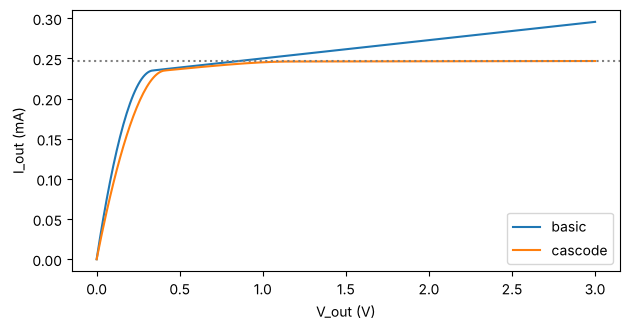

In [2]:
h = 1e-3
r_casc = 2 * h / (cascode(2 + h) - cascode(2 - h))
v99 = brentq(lambda v: cascode(v) - 0.99 * IREF, 0.4, 2.0)
print(f"I_ref = {IREF*1e3:.4f} mA; cascode R_out at 2 V = {r_casc/1e3:.0f} kOhm; 99% of I_ref at {v99:.3f} V")
print(f"basic mirror R_out at 2 V = {2*h/(basic(2+h)-basic(2-h))/1e3:.2f} kOhm")
assert abs(r_casc / 1e3 - 3044) < 0.5 and abs(v99 - 0.894) < 5e-4
v = np.linspace(0, 3, 300)
plt.figure(figsize=(6.4, 3.4))
plt.plot(v, [basic(x) * 1e3 for x in v], label="basic"); plt.plot(v, [cascode(x) * 1e3 for x in v], label="cascode")
plt.axhline(IREF * 1e3, ls=":", color="0.5"); plt.xlabel("V_out (V)"); plt.ylabel("I_out (mA)"); plt.legend()
plt.tight_layout(); plt.show()

## Part 2 · Mismatch Monte Carlo (guided exercise)

$WL$ = 10 µm², $A_{VT}$ = 3.5 mV·µm (illustrative), $V_{OV}$ = 0.2 V: $\Delta I/I = (2/V_{ov})\Delta V_{TH}$.

sigma of the ratio 1.093%; fraction above 2%: 6.58% (prediction 7.08%)


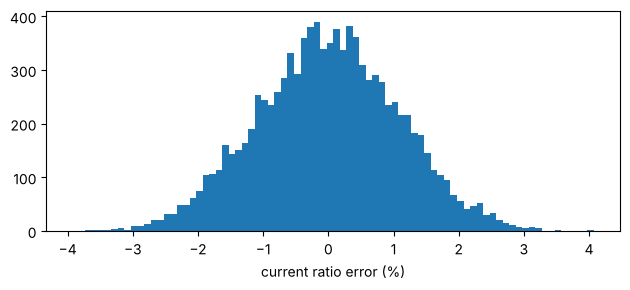

In [3]:
rng = np.random.default_rng(1008)
sigma_vt = 3.5e-3 / math.sqrt(10)
err = (2 / 0.2) * rng.normal(0.0, sigma_vt, 10000)
frac = np.mean(np.abs(err) > 0.02) * 100
pred = 2 * norm.sf(0.02 / ((2 / 0.2) * sigma_vt)) * 100
print(f"sigma of the ratio {err.std()*100:.3f}%; fraction above 2%: {frac:.2f}% (prediction {pred:.2f}%)")
assert abs(frac - 6.58) < 5e-3 and abs(pred - 7.08) < 5e-3
plt.figure(figsize=(6.4, 3.0)); plt.hist(err * 100, bins=80); plt.xlabel("current ratio error (%)")
plt.tight_layout(); plt.show()

## Part 3 · Bipolar mirrors across β

beta = 20: basic -9.091%, helper -0.4739%, Wilson -0.4525%


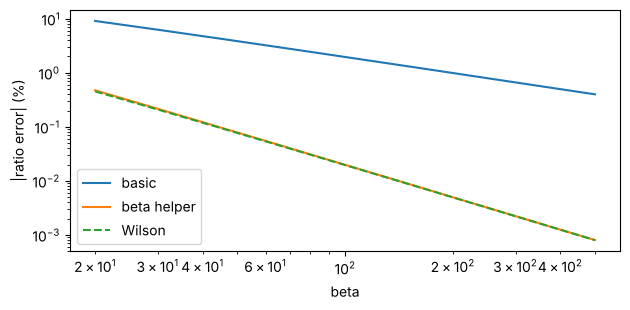

In [4]:
betas = np.linspace(20, 500, 300)
basic_e = (1 / (1 + 2 / betas) - 1) * 100
helper_e = (1 / (1 + 2 / (betas * (betas + 1))) - 1) * 100
wilson_e = -2 / (betas ** 2 + 2 * betas + 2) * 100
print(f"beta = 20: basic {basic_e[0]:.3f}%, helper {helper_e[0]:.4f}%, Wilson {wilson_e[0]:.4f}%")
assert abs(basic_e[0] + 9.09) < 5e-3 and abs(helper_e[0] + 0.474) < 5e-4 and abs(wilson_e[0] + 0.452) < 5e-4
plt.figure(figsize=(6.4, 3.2))
plt.loglog(betas, -basic_e, label="basic"); plt.loglog(betas, -helper_e, label="beta helper"); plt.loglog(betas, -wilson_e, "--", label="Wilson")
plt.xlabel("beta"); plt.ylabel("|ratio error| (%)"); plt.legend(); plt.tight_layout(); plt.show()

## Part 4 · Supply sensitivity of a resistor reference (Example 10-08.7)

I_ref at 3.3 V = 100.015 uA; sensitivity = 37.200 %/V


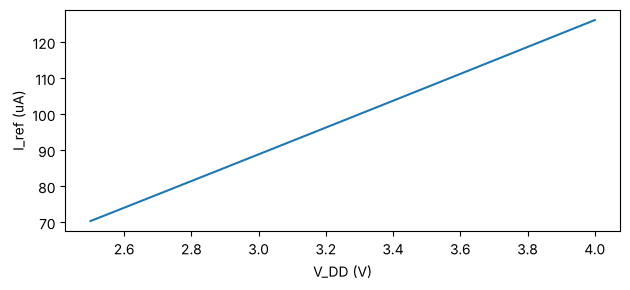

In [5]:
R = 25.76e3

def iref(vdd):
    vg = brentq(lambda x: (vdd - x) / R - 0.5 * K * (x - VTN) ** 2, 0.5, vdd)
    return (vdd - vg) / R

d = 1e-4
sens = (iref(3.3 + d) - iref(3.3 - d)) / (2 * d) / iref(3.3) * 100
print(f"I_ref at 3.3 V = {iref(3.3)*1e6:.3f} uA; sensitivity = {sens:.3f} %/V")
assert abs(sens - 37.20) < 5e-3
vs = np.linspace(2.5, 4.0, 100)
plt.figure(figsize=(6.4, 3.0)); plt.plot(vs, [iref(x) * 1e6 for x in vs]); plt.xlabel("V_DD (V)"); plt.ylabel("I_ref (uA)")
plt.tight_layout(); plt.show()